# Dataset B — Logistic Regression final run

## tl;dr

Notebook báo cáo chỉ đọc cho lineage frozen `lr_final_15f_20261002_01`. Nó trình bày LR-06 đến LR-10 từ canonical final artifacts. Notebook không fit, refit, inference, chọn lại threshold hoặc ghi artifact.

## Context & Methods

Dữ liệu hiển thị được đọc lại từ canonical final bundle. LR-10 kiểm tra trực tiếp final feature contract, `split_v1`, schema 15/19/62, Train-only boundary, OOF coverage, fitted state, ordered holdout records và numerical reproduction; SHA không phải acceptance gate.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'config/dataset_b/model_protocol_v1.yaml').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Cannot locate the Dataset B project root.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset_b.review.lr_final_review import review_lr_final
from src.dataset_b.reporting import (
    cv_fold_frame,
    plot_cv_roc_auc,
    plot_calibration_curve,
    plot_threshold_balanced_accuracy,
)

RUN_ID = 'lr_final_15f_20261002_01'
RUN_DIR = PROJECT_ROOT / 'artifacts/dataset_b/lr/final' / RUN_ID
report_summary = review_lr_final(RUN_ID, run_dir=RUN_DIR)
cv_results = json.loads((RUN_DIR / 'cv_results.json').read_text(encoding='utf-8'))
full_train_result = json.loads((RUN_DIR / 'full_train_result.json').read_text(encoding='utf-8'))
threshold_candidates = pd.read_csv(RUN_DIR / 'validation/threshold_candidates.csv')
print(f"Loaded and validated {report_summary['run_id']} ({report_summary['reporting_status']}).")

Loaded and validated lr_final_15f_20261002_01 (COMPLETE).


### Key Assumptions

- LR-06 đến LR-10 artifacts là nguồn số liệu; notebook không tái tính huấn luyện, inference hoặc threshold.
- LR final bundle đã đóng băng; tổng hợp sáu model là workstream riêng.
- Không dùng threshold lịch sử `0.747` hoặc artifact 66-column.

## Data

### Lineage và stage gates

In [2]:
lineage_table = pd.DataFrame([
    {'Field': 'Model', 'Value': report_summary['model_key']},
    {'Field': 'run_id', 'Value': report_summary['run_id']},
    {'Field': 'Feature version', 'Value': report_summary['feature_version']},
    {'Field': 'Split version', 'Value': report_summary['split_version']},
    {'Field': 'Preprocessing version', 'Value': report_summary['preprocessing_version']},
    {'Field': 'Feature schema', 'Value': '15 raw / 19 semantic / 62 LR'},
])
stage_table = pd.DataFrame([{'Stage': key, 'Status': value} for key, value in report_summary['stages'].items()])
display(lineage_table)
display(stage_table)

,Field,Value
0,Model,lr
1,run_id,lr_final_15f_20261002_01
2,Feature version,feature_set_v1
3,Split version,split_v1
4,Preprocessing version,dataset_b_preprocessing_v2
5,Feature schema,15 raw / 19 semantic / 62 LR


,Stage,Status
0,lr_07,PASS
1,lr_08,PASS
2,lr_09,PASS
3,lr_10,PASS


## Results

### Train-only five-fold CV

In [3]:
cv_table = cv_fold_frame(cv_results, model_key='lr')
cv_summary_table = pd.DataFrame([{
    'Mean ROC-AUC': report_summary['cv']['mean_roc_auc'],
    'Std ROC-AUC (ddof=0)': report_summary['cv']['std_roc_auc'],
    'OOF ROC-AUC': report_summary['cv']['oof_roc_auc'],
    'OOF rows': report_summary['cv']['oof_rows'],
    'Convergence warnings': report_summary['cv']['convergence_warning_count'],
}])
display(cv_summary_table.style.format({'Mean ROC-AUC': '{:.6f}', 'Std ROC-AUC (ddof=0)': '{:.6f}', 'OOF ROC-AUC': '{:.6f}'}))
display(cv_table.style.format({'roc_auc': '{:.6f}', 'fit_seconds': '{:.3f}'}))

,Mean ROC-AUC,Std ROC-AUC (ddof=0),OOF ROC-AUC,OOF rows,Convergence warnings
0,0.816543,0.001805,0.816507,205310,0


,model_key,fold,train_rows,fold_validation_rows,roc_auc,fit_seconds,convergence_warning_count
0,lr,1,164248,41062,0.815598,0.955,0
1,lr,2,164248,41062,0.815125,0.710,0
2,lr,3,164248,41062,0.818844,0.486,0
3,lr,4,164248,41062,0.814565,0.791,0
4,lr,5,164248,41062,0.818585,0.905,0


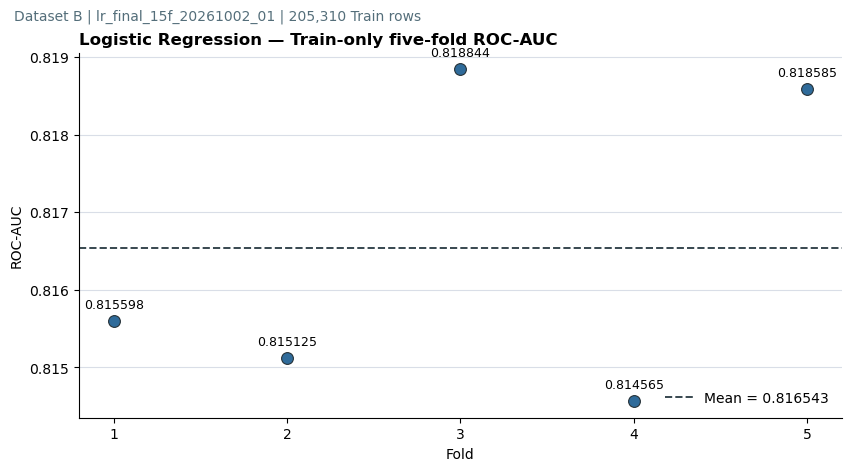

In [4]:
figure, axis = plot_cv_roc_auc(cv_table, model_key='lr', mean_roc_auc=report_summary['cv']['mean_roc_auc'])
axis.set_title('Logistic Regression — Train-only five-fold ROC-AUC', loc='left', fontweight='bold')
figure.suptitle(f"Dataset B | {RUN_ID} | 205,310 Train rows", x=0.01, ha='left', fontsize=10, color='#546E7A')
import matplotlib.pyplot as plt
plt.show()

### Fresh full-Train fit

In [5]:
full_train_table = pd.DataFrame([{
    'Train rows': report_summary['full_train']['fit_rows'],
    'Encoded features': report_summary['feature_counts']['model_input'],
    'Matrix': f"{full_train_result['matrix_format']} {full_train_result['matrix_dtype']}",
    'Finite': full_train_result['matrix_finite'],
    'Iterations': max(report_summary['full_train']['n_iter']),
    'Fit seconds': report_summary['full_train']['fit_seconds'],
    'Convergence warnings': report_summary['full_train']['convergence_warning_count'],
    'Reload predictions exact': full_train_result['reload_predictions_exact'],
}])
display(full_train_table.style.format({'Fit seconds': '{:.3f}'}))

,Train rows,Encoded features,Matrix,Finite,Iterations,Fit seconds,Convergence warnings,Reload predictions exact
0,205310,62,csr float64,True,97,2.852,0,True


### Validation prediction và threshold

LR-08 đọc frozen full-Train bundle đúng một lượt inference, sau đó tối đa hóa Balanced Accuracy trên Validation. Bảng và biểu đồ dưới đây chỉ đọc artifact đã đóng băng; không dùng số liệu từ `lr_baseline_v1`.

,Validation rows,Unique ordered IDs,Selected threshold,Balanced Accuracy,Recall approved,Recall denied,Maximizer count,Probability min,Probability max
0,43995,43995,0.493,0.736301,0.840190,0.632412,1,0.000000,0.999969


**Stages đang chờ:** Không có

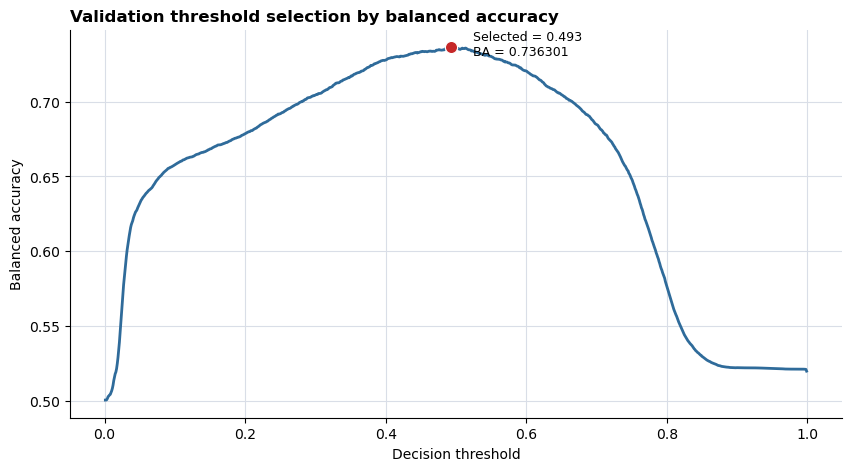

In [6]:
validation = report_summary['validation']
validation_table = pd.DataFrame([{
    'Validation rows': validation['rows'],
    'Unique ordered IDs': validation['unique_record_ids'],
    'Selected threshold': validation['threshold'],
    'Balanced Accuracy': validation['balanced_accuracy'],
    'Recall approved': validation['recall_approved'],
    'Recall denied': validation['recall_denied'],
    'Maximizer count': validation['maximizer_count'],
    'Probability min': validation['probability_min'],
    'Probability max': validation['probability_max'],
}])
display(validation_table.style.format({
    'Selected threshold': '{:.3f}',
    'Balanced Accuracy': '{:.6f}',
    'Recall approved': '{:.6f}',
    'Recall denied': '{:.6f}',
    'Probability min': '{:.6f}',
    'Probability max': '{:.6f}',
}))
figure, axis = plot_threshold_balanced_accuracy(
    threshold_candidates, model_key='lr', selected_threshold=validation['threshold']
)
pending = stage_table.loc[stage_table['Status'].eq('PENDING'), 'Stage'].tolist()
display(Markdown('**Stages đang chờ:** ' + (', '.join(pending) if pending else 'Không có')))

### Test / RQ1 evaluation

LR-09 dùng frozen model/preprocessing và threshold LR-08 để inference Test đúng một lượt. Các metric và CI dưới đây đọc trực tiếp từ RQ1 artifact đã đóng băng.

,Metric,Point estimate,95% CI low,95% CI high,Valid bootstrap replicates
0,average_precision_denied,0.696305,0.689280,0.703901,1000
1,balanced_accuracy,0.738384,0.733361,0.743290,1000
2,calibration_intercept,1.060342,1.044740,1.074985,1000
3,calibration_slope,1.020844,0.996750,1.046312,1000
4,f1_denied,0.605050,0.598142,0.611809,1000
5,precision_denied,0.578312,0.571138,0.585331,1000
6,recall_approved,0.842389,0.838336,0.846382,1000
7,recall_denied,0.634380,0.624899,0.642966,1000
8,roc_auc_approved,0.817944,0.813012,0.822304,1000
9,brier_score_approved,0.160129,0.158507,0.161796,1000


## Takeaways
- LR-06 đến LR-10 cùng lineage `lr_final_15f_20261002_01` đã vượt direct review và reporting checks.
- Test ROC-AUC = **0.817944**; Balanced Accuracy = **0.738384**.
- Threshold Validation được giữ nguyên ở **0.493**; 1.000 bootstrap replicate hợp lệ cho mọi metric.
- LR final review đã PASS; notebook 07 chỉ mở khi đủ sáu model final.

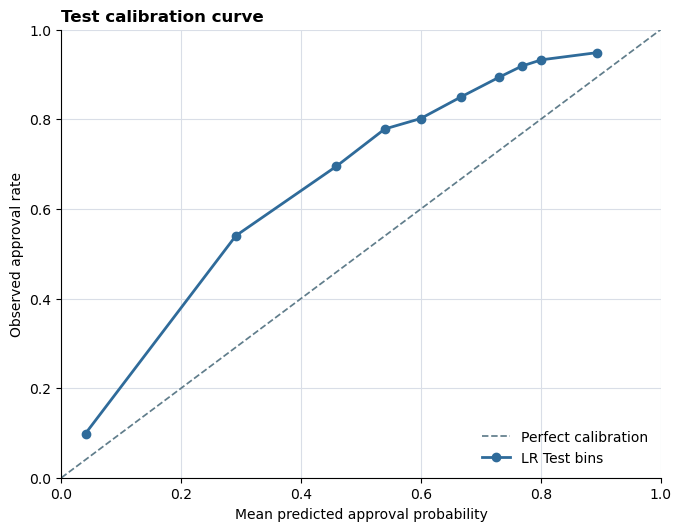

In [7]:
test = report_summary['test']
metrics = test['point_metrics']
intervals = test['confidence_intervals_95_percentile']
metric_table = pd.DataFrame([
    {'Metric': name, 'Point estimate': metrics[name], '95% CI low': intervals[name]['lower_2_5'], '95% CI high': intervals[name]['upper_97_5'], 'Valid bootstrap replicates': intervals[name]['valid_replicates']}
    for name in metrics
])
display(metric_table.style.format({'Point estimate': '{:.6f}', '95% CI low': '{:.6f}', '95% CI high': '{:.6f}'}))
figure, axis = plot_calibration_curve(test['calibration_curve'], model_key='lr')
display(Markdown(
    '## Takeaways\n'
    f"- LR-06 đến LR-10 cùng lineage `{RUN_ID}` đã vượt direct review và reporting checks.\n"
    f"- Test ROC-AUC = **{metrics['roc_auc_approved']:.6f}**; Balanced Accuracy = **{metrics['balanced_accuracy']:.6f}**.\n"
    f"- Threshold Validation được giữ nguyên ở **{test['threshold']:.3f}**; 1.000 bootstrap replicate hợp lệ cho mọi metric.\n"
    '- LR final review đã PASS; notebook 07 chỉ mở khi đủ sáu model final.'
))